# Linear Algebra Review and SciPy Basics

Definitions and notation in this review follow Section **2.2 Vectors and Matrices** in Biegler (2010), with the invertibility discussion cross-checked against Lay, *Linear Algebra and Its Applications*, 3rd ed.

**Recommended Links**
* [NumPy Documentation - Main Page](https://docs.scipy.org/doc/numpy-1.15.0/reference/)
* [SciPy Documentation - Main Page](https://docs.scipy.org/doc/scipy-1.1.0/reference/)
* [SciPy Linear Algebra - Tutorial](https://docs.scipy.org/doc/scipy-1.1.0/reference/tutorial/linalg.html)
* [SciPy Linear Algebra - API](https://docs.scipy.org/doc/scipy-1.1.0/reference/linalg.html)
* [SciPy Lecture Notes](http://www.scipy-lectures.org/) (Especially 1.1 - 1.6 for everyone and 2.1 - 2.2 for advanced users)

Tip: We will mostly use SciPy for linear algebra. (It has more sophisticated capabilities than NumPy.) We will use NumPy if/when SciPy does not offer a specific command.

In [1]:
# Load required Python libraries.
import numpy as np
from scipy import linalg

# Seed the random number generator so this notebook is reproducible
# (Pyomo style guide, section 8).
np.random.seed(0)

## Notation used in the references
* Scalar constants and variables - Greek letters
* Vectors - Lower case Roman letters
* Matrices - Upper case Roman letters

The notation for lectures will (hopefully) be obvious from context. I sometimes use Greek letters for constants and Roman letters for variables... unless the Greek letters have engineering or scientific meaning.

## Matrix Operations

For $\mathbf{A}\in\mathbb{R}^{n\times m}$ and $\mathbf{B}\in\mathbb{R}^{m\times p}$, the product $\mathbf{C}=\mathbf{AB}\in\mathbb{R}^{n\times p}$ has entries

$$C_{ij}=\sum_{k=1}^{m}A_{ik}B_{kj}.$$

The inner dimensions must match. The transpose interchanges rows and columns, $(\mathbf{A}^\mathsf{T})_{ij}=A_{ji}$. A square matrix is **symmetric** when $\mathbf{A}=\mathbf{A}^\mathsf{T}$, **diagonal** when $A_{ij}=0$ for $i\ne j$, and the identity has $I_{ij}=1$ for $i=j$ and zero otherwise.

In [2]:
# Generate random matrices
n = 2
m = 3

Ao = np.random.rand(n, m)
Bo = np.random.rand(m, n)

print("Ao = ")
print(Ao)
print("\nBo = ")
print(Bo)


# What is the dimension of A*B? Try to answer this without the computer.

# Calculate A*B using Python
print("\nAo*Bo =")
print(Ao.dot(Bo))

Ao = 
[[0.5488135  0.71518937 0.60276338]
 [0.54488318 0.4236548  0.64589411]]

Bo = 
[[0.43758721 0.891773  ]
 [0.96366276 0.38344152]
 [0.79172504 0.52889492]]

Ao*Bo =
[[1.40657799 1.08244885]
 [1.15806481 0.98996907]]


**Activity**
* Calculate $\mathbf{A}_o^{T}$
* Create a square matrix and check if it is symmetric
* Create a 3x3 identity matrix

In [3]:
# Transpose
print("transpose(Ao) = \n", Ao.transpose(), "\n")

# Create a square matrix. Is it symmetric?

# Identify matrix
print("I = \n", np.identity(3), "\n")

transpose(Ao) = 
 [[0.5488135  0.54488318]
 [0.71518937 0.4236548 ]
 [0.60276338 0.64589411]] 

I = 
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]] 



## Determinant

For a square matrix $\mathbf{A}\in\mathbb{R}^{n\times n}$, expansion along any row $i$ gives

$$\det(\mathbf{A})=\sum_{j=1}^{n}(-1)^{i+j}A_{ij}\,\bar A_{ij},$$

where $A_{ij}$ is the entry in row $i$ and column $j$, and $\bar A_{ij}$ is the determinant of the $(n-1)\times(n-1)$ matrix obtained by deleting row $i$ and column $j$ from $\mathbf{A}$. Useful properties are

$$\det(\mathbf{AB})=\det(\mathbf{A})\det(\mathbf{B}),\qquad \det(\mathbf{A}^\mathsf{T})=\det(\mathbf{A}),\qquad \det(\alpha \mathbf{A})=\alpha^n\det(\mathbf{A}),\qquad \det(\mathbf{I})=1.$$

The exponent $n$ in the scaling law matters: multiplying the whole matrix by $\alpha$ scales each of its $n$ rows. A square matrix is singular exactly when $\det(\mathbf{A})=0$.

In [4]:
# Generate random matrices
nd = 2

Ad = np.random.rand(nd, nd)
Bd = np.random.rand(nd, nd)

Cd = np.array([(1, 0, 0), (-2, 0, 0), (0, 1, 1)])

print("Ad = ")
print(Ad)
print("\nBd = ")
print(Bd)
print("\nCd = ")
print(Cd)

Ad = 
[[0.56804456 0.92559664]
 [0.07103606 0.0871293 ]]

Bd = 
[[0.0202184  0.83261985]
 [0.77815675 0.87001215]]

Cd = 
[[ 1  0  0]
 [-2  0  0]
 [ 0  1  1]]


**Activity**
* Verify the properties listed under *Some properties for the determinant include*
* Are $\mathbf{A}_d$, $\mathbf{B}_d$ or $\mathbf{C}_d$ singular?

In [5]:
# Property 1
print("det(A*B) = ", linalg.det(Ad.dot(Bd)))

print("det(A)*det(B) = ", linalg.det(Ad) * linalg.det(Bd))

det(A*B) =  0.010247347495272154
det(A)*det(B) =  0.010247347495272162


In [6]:
# Property 2

In [7]:
# Property 3

In [8]:
# Property 4

**Another Example** (for at home)

Expand along the first row of

$$\mathbf{A}=\begin{bmatrix}1&5&0\\2&4&-1\\0&-2&0\end{bmatrix}.$$

Then

$$\det(\mathbf{A})=1\det\begin{bmatrix}4&-1\\-2&0\end{bmatrix}-5\det\begin{bmatrix}2&-1\\0&0\end{bmatrix}+0\det\begin{bmatrix}2&4\\0&-2\end{bmatrix}=-2.$$

This is the worked example previously shown as a crop from Lay; it is written natively here so the signs and arithmetic remain searchable and accessible.

## Rank

The rank of $\mathbf{A}\in\mathbb{R}^{n\times m}$ is the dimension of its column space (equivalently, its row space). It is also the size of the largest square submatrix with nonzero determinant. Full rank means $\operatorname{rank}(\mathbf{A})=\min(n,m)$; otherwise $\mathbf{A}$ is rank deficient.

**Activity**
* Predict the rank of $\mathbf{A}_o^T$, $\mathbf{B}_o^T$, $\mathbf{A}_d$, $\mathbf{B}_d$, $\mathbf{C}_d$
* Calculate np.linalg.matrix_rank(). Were you correct?

In [9]:
print("rank(A_o) = ", np.linalg.matrix_rank(Ao), "\n")

# Fill in remainder here.

rank(A_o) =  2 



## Inverse

A square matrix $\mathbf{A}$ is invertible when there is a matrix $\mathbf{A}^{-1}$ satisfying $\mathbf{AA}^{-1}=\mathbf{A}^{-1}\mathbf{A}=\mathbf{I}$. Then $\mathbf{Ax}=\mathbf{b}$ has the unique solution $\mathbf{x}=\mathbf{A}^{-1}\mathbf{b}$, although numerical software should solve the system directly rather than form the inverse. Also, $\det(\mathbf{A}^{-1})=1/\det(\mathbf{A})$. An orthogonal matrix $\mathbf{Q}$ satisfies $\mathbf{Q}^{-1}=\mathbf{Q}^\mathsf{T}$.

**Activity**
1. Calculate the inverse of the square matrix $\mathbf{A}_d$ and verify that $\mathbf{A}_d^{-1} \mathbf{A}_d = \mathbf{I}$. (The rectangular matrix $\mathbf{A}_o$ has no two-sided inverse.)
2. Verify that $\det(\mathbf{A}_d^{-1}) = 1/\det(\mathbf{A}_d)$
3. Is $\mathbf{Q}$ an orthogonal matrix?

In [10]:
# Task 1

# Task 2

# Task 3
# Is this an orthogonal matrix? Yes, no, or need more information?
theta = 0.2
Q = np.array([(np.cos(theta), -np.sin(theta)), (np.sin(theta), np.cos(theta))])

print("Q = ")
print(Q)

Q = 
[[ 0.98006658 -0.19866933]
 [ 0.19866933  0.98006658]]


## Solving Linear Systems
Consider the linear system $\mathbf{A}_l \mathbf{x} = b_l$

In [11]:
Al = np.array([(4, 3), (6, 3)])
bl = np.array([1, 0])
print("Al = \n", Al)
print("\nbl = \n", bl)

Al = 
 [[4 3]
 [6 3]]

bl = 
 [1 0]


### Explicit Inverse

Calculate $\mathbf{x}$ by explicitly using $\mathbf{A}_l^{-1}$. Hint: Use linalg.inv().

In [12]:
Ainv = linalg.inv(Al)
print("Ainv = \n", Ainv, "\n")

# Now calculate and print x

Ainv = 
 [[-0.5         0.5       ]
 [ 1.         -0.66666667]] 



### LU Decomposition

Perform LU decomposition on $\mathbf{A}_l$. What structures do the $\mathbf{P}$, $\mathbf{L}$, and $\mathbf{U}$ matrices have?

In [13]:
# Create test linear systems
# The transpose is deliberate: it gives a permutation matrix P that is NOT
# symmetric, so the MATLAB and SciPy conventions below give different answers.
A = np.random.rand(4, 4).T
print("A = \n", A, "\n")

b = np.random.rand(4, 1)
print("b = \n", b, "\n")

A = 
 [[0.97861834 0.11827443 0.52184832 0.45615033]
 [0.79915856 0.63992102 0.41466194 0.56843395]
 [0.46147936 0.14335329 0.26455561 0.0187898 ]
 [0.78052918 0.94466892 0.77423369 0.6176355 ]] 

b = 
 [[0.61209572]
 [0.616934  ]
 [0.94374808]
 [0.6818203 ]] 



In [14]:
# Perform LU decomposition
P, L, U = linalg.lu(A)

# Permutation matrix
print("P = \n", P)

# Lower triangular matrix
print("L = \n", L)

# Upper triangular matrix
print("U = \n", U)

# Verify result
print("P*L*U = \n", P.dot(L.dot(U)), "\n")

P = 
 [[1. 0. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]]
L = 
 [[1.         0.         0.         0.        ]
 [0.79758282 1.         0.         0.        ]
 [0.81661924 0.63896662 1.         0.        ]
 [0.47156214 0.10299414 0.07659477 1.        ]]
U = 
 [[ 0.97861834  0.11827443  0.52184832  0.45615033]
 [ 0.          0.85033527  0.35801643  0.25381783]
 [ 0.          0.         -0.24024999  0.03375169]
 [ 0.          0.          0.         -0.22504038]]
P*L*U = 
 [[0.97861834 0.11827443 0.52184832 0.45615033]
 [0.79915856 0.63992102 0.41466194 0.56843395]
 [0.46147936 0.14335329 0.26455561 0.0187898 ]
 [0.78052918 0.94466892 0.77423369 0.6176355 ]] 



#### Is P orthogonal?

In [15]:
print("inv(P) = \n", linalg.inv(P), "\n")

print("transpose(P) = \n", P.T, "\n")

print("P.T*P = \n", np.matmul(P.T, P), "\n")

inv(P) = 
 [[ 1.  0. -0.  0.]
 [ 0.  0. -0.  1.]
 [ 0.  1. -0.  0.]
 [ 0.  0.  1.  0.]] 

transpose(P) = 
 [[1. 0. 0. 0.]
 [0. 0. 0. 1.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]] 

P.T*P = 
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 



**Yes!** We see that $\mathbf{P}^T = \mathbf{P}^{-1}$ and $\mathbf{P}^T \cdot \mathbf{P} = \mathbf{I}$.

#### MATLAB

Defines LU decomposition as follows:

$$ \mathbf{P} \cdot \mathbf{A} = \mathbf{L} \cdot \mathbf{U}$$

Consider $$\mathbf{A} \cdot \mathbf{x}=\mathbf{b}$$

Using MATLAB LU definition

$$\mathbf{P}\cdot \mathbf{A} = \mathbf{L}\cdot \mathbf{U}$$
$$\mathbf{P}^T \cdot \mathbf{P} \cdot \mathbf{A} = \mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U}$$
$$\mathbf{A} = \mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U}$$

Substitute into linear system:

$$\mathbf{P}^T \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{b}$$
$$ \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P} \cdot \mathbf{b}$$

Let $\mathbf{y} = \mathbf{U} \cdot \mathbf{x}$ and substitute.

Step 1. Solve $\mathbf{L} \cdot \mathbf{y} = \mathbf{P} \cdot \mathbf{b}$ for $\mathbf{y}$

Step 2. Solve $\mathbf{U} \cdot \mathbf{x} = \mathbf{y}$ for $\mathbf{x}$

In [16]:
Pb = P.dot(b)
print("P*b = ", Pb, "\n")

yLU = linalg.solve(L, Pb)
print("yLU = ", yLU, "\n")

xLU = linalg.solve(U, yLU)
print("xLU = ", xLU, "\n")

# Check: does this x actually solve A*x = b?
print("||A*x - b|| = ", np.linalg.norm(A.dot(xLU) - b), "\n")

P*b =  [[0.61209572]
 [0.94374808]
 [0.6818203 ]
 [0.616934  ]] 

yLU =  [[ 0.61209572]
 [ 0.45555105]
 [-0.10911075]
 [ 0.28973105]] 

xLU =  [[ 0.98256068]
 [ 0.80496658]
 [ 0.27328499]
 [-1.28746252]] 

||A*x - b|| =  0.42382052546128374 



#### SciPy

Defines LU decomposition as:

$$ \mathbf{A} = \mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} $$

Consider $$\mathbf{A} \cdot \mathbf{x}=\mathbf{b}$$

SciPy LU definition

$$\mathbf{A} = \mathbf{P} \cdot \mathbf{L}\cdot \mathbf{U}$$

Substitute into linear system:

$$\mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{b}$$
$$\mathbf{P}^T \cdot \mathbf{P} \cdot \mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P}^T \cdot \mathbf{b}$$
$$\mathbf{L} \cdot \mathbf{U} \cdot \mathbf{x} = \mathbf{P}^T \cdot \mathbf{b}$$

Let $\mathbf{y} = \mathbf{U} \cdot \mathbf{x}$ and substitute.

Step 1. Solve $\mathbf{L} \cdot \mathbf{y} = \mathbf{P}^T \cdot \mathbf{b}$ for $\mathbf{y}$

Step 2. Solve $\mathbf{U} \cdot \mathbf{x} = \mathbf{y}$ for $\mathbf{x}$

In [17]:
## LU decomposition algorithm.
Pb = (P.T).dot(b)
print("P.T*b = ", Pb, "\n")

yLU = linalg.solve(L, Pb)
print("yLU = ", yLU, "\n")

xLU = linalg.solve(U, yLU)
print("xLU = ", xLU, "\n")

# Check: does this x actually solve A*x = b?
print("||A*x - b|| = ", np.linalg.norm(A.dot(xLU) - b), "\n")

P.T*b =  [[0.61209572]
 [0.6818203 ]
 [0.616934  ]
 [0.94374808]] 

yLU =  [[ 0.61209572]
 [ 0.19362327]
 [-0.00663395]
 [ 0.63567297]] 

xLU =  [[ 1.99078818]
 [ 1.22630486]
 [-0.3692182 ]
 [-2.82470629]] 

||A*x - b|| =  3.6821932062951477e-16 



**What is the difference?** A transpose.


#### Verify our answer with `linalg.solve`

Solve the linear system using linalg.solve

In [18]:
x = linalg.solve(Al, bl)
print("x = \n", x)

x = 
 [-0.5  1. ]


## Invertible Matrix Theorem

For a square $n\times n$ matrix $\mathbf{A}$, the following statements are equivalent:

* $\mathbf{A}$ is invertible; its row-reduced form is $\mathbf{I}$; and it has $n$ pivots.
* $\mathbf{Ax}=\mathbf{0}$ has only the trivial solution, so $\operatorname{Nul}(\mathbf{A})=\{\mathbf{0}\}$ and $\dim\operatorname{Nul}(\mathbf{A})=0$.
* The columns of $\mathbf{A}$ are linearly independent, form a basis of $\mathbb{R}^n$, and span $\mathbb{R}^n$; equivalently $\operatorname{rank}(\mathbf{A})=n$.
* The map $\mathbf{x}\mapsto \mathbf{Ax}$ is both one-to-one and onto; therefore $\mathbf{Ax}=\mathbf{b}$ has a solution for every $\mathbf{b}\in\mathbb{R}^n$.
* A left or right inverse exists; $\mathbf{A}^\mathsf{T}$ is invertible; $\det(\mathbf{A})\ne0$; and zero is not an eigenvalue.
* The row space is $\mathbb{R}^n$, $(\operatorname{Col}\mathbf{A})^\perp=\{\mathbf{0}\}$, $(\operatorname{Nul}\mathbf{A})^\perp=\mathbb{R}^n$, and $\mathbf{A}$ has $n$ nonzero singular values.

These equivalences consolidate Lay's Invertible Matrix Theorem into one searchable list.

## Eigenvectors and Eigenvalues

For square $\mathbf{A}$, a nonzero vector $\mathbf{v}$ is an eigenvector with eigenvalue $\lambda$ when $\mathbf{Av}=\lambda \mathbf{v}$. Thus $\mathbf{A}-\lambda \mathbf{I}$ is singular and eigenvalues are roots of $\det(\mathbf{A}-\lambda \mathbf{I})=0$. Counting algebraic multiplicity, $\det(\mathbf{A})=\prod_i\lambda_i$.

If $\mathbf{A}$ is real and symmetric, the spectral theorem gives $\mathbf{A}=\mathbf{V}\boldsymbol{\Lambda} \mathbf{V}^\mathsf{T}$ with real eigenvalues and orthonormal eigenvectors. Only under this symmetry assumption can definiteness be read directly from eigenvalue signs: all positive means positive definite, all nonnegative means positive semidefinite, and mixed signs mean indefinite.

A nonsymmetric real matrix may have complex eigenvalues, and its eigenvalues do **not** in general classify the quadratic form $\mathbf{x}^\mathsf{T}\mathbf{Ax}$. That form is governed by the symmetric part $(\mathbf{A}+\mathbf{A}^\mathsf{T})/2$. For rectangular matrices, singular values $\sigma_i\ge0$—the square roots of the eigenvalues of $\mathbf{A}^\mathsf{T}\mathbf{A}$—play the analogous role.

### Level sets of a quadratic form, as one picture

![Level sets of the quadratic form $q(\mathbf{x})=\tfrac12 \mathbf{x}^\mathsf{T} \mathbf{A} \mathbf{x}$ for symmetric positive definite $\mathbf{A}$, with the eigenvectors drawn as the principal axes. Both panels use the same eigenvectors and the same level $q=2$; only the eigenvalues change.](../../media/figures/quadratic-form-level-sets.png)

Eigenvalues and eigenvectors of a **symmetric** matrix have a picture: they are the principal
axes of the level sets of $q(\mathbf{x}) = \tfrac12 \mathbf{x}^\mathsf{T} \mathbf{A} \mathbf{x}$. In the rotated coordinates
$\mathbf{z} = \mathbf{V}^\mathsf{T} \mathbf{x}$ the level set is $\lambda_1 z_1^2 + \lambda_2 z_2^2 = 2q$, so the
semi-axis along $v_i$ has length $\sqrt{2q/\lambda_i} \propto 1/\sqrt{\lambda_i}$ --- a
large eigenvalue means *steep*, hence *short*.

The right-hand panel is the same picture with a condition number of 100. Here $K(\mathbf{A})=\lambda_{\max}/\lambda_{\min}$ is the condition number of a symmetric positive definite matrix (defined properly in the **Condition Number** section below). Note the axis ratio
is $\sqrt{K(\mathbf{A})}$, not $K(\mathbf{A})$. The matrices in **Four Factorizations, Four Failures** below have $K(\mathbf{A})$ from about $10^{8}$ to $10^{18}$, and for those the ellipse is not drawable.

This figure is rendered from `figures/plots/quadratic-form-level-sets.py` and is the **same
image printed in the course pack**, so what you annotate in lecture and what you see here
cannot drift apart. The cells below are the live version.


In [19]:
Ae = np.array([(0, -4, -6), (-1, 0, -3), (1, 2, 5)])
print("Ae = \n", Ae)

Ae = 
 [[ 0 -4 -6]
 [-1  0 -3]
 [ 1  2  5]]


**Activity**
* Do you expect this matrix to have negative eigenvalues? Choose: Yes / No / Cannot tell from inspection.
* Calculate the eigenvalues.
* The eigenvalues of this nonsymmetric matrix are positive. Does that prove $\mathbf{x}^\mathsf{T}\mathbf{A}_e \mathbf{x}>0$ for every nonzero $\mathbf{x}$?
* Form the symmetric part $\mathbf{H}=(\mathbf{A}_e+\mathbf{A}_e^\mathsf{T})/2$ and use its eigenvalues to classify the quadratic form.
* Calculate $\det(\mathbf{A}_e)$ using only the eigenvalues of $\mathbf{A}_e$.

In [20]:
# Expect negative eigenvalues?
# Yes / No / Cannot tell from inspection?
# Write a sentence to justify your answer.

### Calculate eigenvalues

# Matrix Ae is nonsymmetric
print("Matrix = \n", Ae, "\n")
l, v = linalg.eig(Ae)
print("Eigenvalues = ", l, "\n")
print("Eigenvectors = \n", v, "\n")

# The symmetric part, not Ae's eigenvalues, classifies x.T @ Ae @ x
H = 0.5 * (Ae + Ae.T)
print("Eigenvalues of symmetric part = ", linalg.eigvalsh(H))

Matrix = 
 [[ 0 -4 -6]
 [-1  0 -3]
 [ 1  2  5]] 

Eigenvalues =  [1.+0.j 2.+0.j 2.+0.j] 

Eigenvectors = 
 [[-0.81649658 -0.95681941 -0.06734698]
 [-0.40824829  0.04849614 -0.81965465]
 [ 0.40824829  0.28660904  0.56888543]] 

Eigenvalues of symmetric part =  [-3.08257569  2.          6.08257569]


## Singular Value Decomposition
Notes will be given in class.

**Activity**
* Calculate singular value decomposition of $\mathbf{A}_l$ and $\mathbf{C}_d$
* What is the rank of each matrix?

In [21]:
# Matrix Al
print("Matrix = \n", Al, "\n")
U, s, Vh = linalg.svd(Al)
print("U = \n", U, "\n")
print("S = \n", s, "\n")
print("Vh = \n", Vh, "\n")

## Rank (from inspecting singular values)?

Matrix = 
 [[4 3]
 [6 3]] 

U = 
 [[-0.59581566 -0.80312122]
 [-0.80312122  0.59581566]] 

S = 
 [8.33557912 0.71980602] 

Vh = 
 [[-0.86400595 -0.50348159]
 [ 0.50348159 -0.86400595]] 



## Vector and Matrix Norms

A **vector norm** $||\mathbf{x}||$ measures the length of a vector. It maps $\mathbb{R}^n$ into the nonnegative reals and satisfies three properties:

$$||\mathbf{x}|| = 0 \Rightarrow \mathbf{x} = \mathbf{0}, \qquad ||\alpha \mathbf{x}|| = |\alpha| \cdot ||\mathbf{x}||, \qquad ||\mathbf{x} + \mathbf{y}|| \leq ||\mathbf{x}|| + ||\mathbf{y}||$$

The last one is the *triangle inequality*. The **$p$-norm** is $||\mathbf{x}||_p = \left( \sum_{i=1}^n |x_i|^p \right)^{1/p}$ for $p \geq 1$, and three cases matter here:

* $||\mathbf{x}||_1 = \sum_{i=1}^n |x_i|$ --- the 1-norm
* $||\mathbf{x}||_2 = \left( \sum_{i=1}^n x_i^2 \right)^{1/2} = \sqrt{\mathbf{x}^T \mathbf{x}}$ --- the Euclidean norm
* $||\mathbf{x}||_{\infty} = \max_i |x_i|$ --- the max norm

Also $|\mathbf{x}^T \mathbf{y}| \leq ||\mathbf{x}||_p \cdot ||\mathbf{y}||_q$ whenever $1/p + 1/q = 1$; the case $p = q = 2$ is the Cauchy-Schwarz inequality.

**Matrix norms** are *induced* by vector norms:

$$||\mathbf{A}|| = \max_{\mathbf{x} \neq \mathbf{0}} \frac{||\mathbf{Ax}||}{||\mathbf{x}||} \qquad \Rightarrow \qquad ||\mathbf{Ax}|| \leq ||\mathbf{A}|| \cdot ||\mathbf{x}||$$

The rules for the three induced norms are

* $||\mathbf{A}||_1 = \max_j \sum_i |A_{ij}|$ --- largest column sum
* $||\mathbf{A}||_{\infty} = \max_i \sum_j |A_{ij}|$ --- largest row sum
* $||A||_2 = $ the largest singular value of $\mathbf{A}$

Finally, the induced norms and the Frobenius norm $||\mathbf{A}||_F = \left( \sum_i \sum_j A_{ij}^2 \right)^{1/2}$ all satisfy

$$||\mathbf{AB}|| \leq ||\mathbf{A}|| \cdot ||\mathbf{B}||$$

for any two compatible matrices $\mathbf{A}$ and $\mathbf{B}$. This is **submultiplicativity**, and it is what the condition number in the next section rests on.

Definition 2.7, pp. 21-22 in Biegler (2010).

In [22]:
x = np.random.rand(3, 1)
print("x = \n", x)

y = np.random.rand(3, 1)
print("y = \n", y)

x = 
 [[0.3595079 ]
 [0.43703195]
 [0.6976312 ]]
y = 
 [[0.06022547]
 [0.66676672]
 [0.67063787]]


**Activity**
* Verify the vector norm properties hold for the p-2 norm using $\mathbf{x}$ and $\mathbf{y}$. Hint: linalg.norm()
* Calculate $||\mathbf{A}_l||_1$, $||\mathbf{A}_l||_{\infty}$ and $||\mathbf{A}_l||_2$ using both the rules given above and SciPy

## Condition Number

**Activity**
* Estimate the condition number of $\mathbf{A}_l$ by inspecting the SVD results.
* Calculate the condition number of $\mathbf{A}_l$ using np.linalg.cond()

## Four Factorizations, Four Failures

Everything above has been a factorization that works. Here are the same four failing, in isolation: no objective function, no solver, and no iteration anywhere near them. Each one is a small matrix and a printed contradiction, and each one comes back later in the course *inside* an algorithm, where four things could be wrong at once. Meet them here, where only one thing can be.

**Every number below is computed when you run the cell.** Nothing is transcribed from the handout, and nothing is hard coded.

> **A note before you start: your tables may not match the handout's, and that is not a mistake.**
> These demos sit right at the edge of double precision, so the exact digits, and sometimes the exact row on which a failure first appears, depend on the LAPACK library underneath NumPy and SciPy. The same code was run on two Python stacks while this notebook was written: on one, D4 first disagrees at $\varepsilon=10^{-9}$; on another, at $\varepsilon=10^{-10}$. Google Colab is a third stack again. What is robust is the **pattern** - a well-conditioned problem, a factorization that quietly lies about it, two library routines that disagree with the truth and with each other. If your table differs from the printed one, you have not done anything wrong; you have found the point, which is that the answer depends on the machine.

> **Two of the cells below deliberately produce an error or a wrong answer.** That is the demonstration, not a defect: D2 makes `scipy.linalg.cholesky` raise a `LinAlgError` on a matrix that is provably positive definite, and D4 makes `scipy.linalg.ldl` report the wrong inertia. Please do not "fix" them.


### D1. LU: partial pivoting does nothing, and a well-conditioned problem still loses its digits

Wilkinson's matrix has $1$ on the diagonal, $-1$ below it, and a last column of all ones. Pick an $\mathbf{x}$, form $\mathbf{b}=\mathbf{Ax}$, solve, and compare with the $\mathbf{x}$ you started from.

Watch the **condition number column**: it crawls from about $9$ to about $31$ across the whole sweep. The problem stays about as well conditioned as a problem gets. Only the algorithm fails.


In [23]:
# D1: LU with partial pivoting on Wilkinson's matrix.
import numpy as np
from scipy import linalg

rng = np.random.default_rng(0)


def wilkinson(n):
    """1 on the diagonal, -1 below it, last column all ones."""
    A = np.eye(n) - np.tril(np.ones((n, n)), -1)
    A[:, -1] = 1.0
    return A


print("A for n = 5:")
print(wilkinson(5).astype(int), "\n")

header = "{:>4} {:>8} {:>14} {:>14} {:>14} {:>9} {:>9}"
row = "{:>4d} {:>8.1f} {:>14.1e} {:>14.1e} {:>14.1e} {:>9.1e} {:>9}"
print(header.format("n", "K(A)", "growth", "2^(n-1)", "rel. resid",
                    "rel. err", "P == I ?"))

for n in [20, 30, 40, 50, 60, 70]:
    A = wilkinson(n)
    x_true = rng.standard_normal(n)
    b = A @ x_true

    P, L, U = linalg.lu(A)
    growth = np.abs(U).max() / np.abs(A).max()

    x_hat = linalg.solve(A, b)
    rel_resid = np.linalg.norm(A @ x_hat - b) / (np.linalg.norm(A)
                                                 * np.linalg.norm(x_hat))
    rel_err = np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)

    print(row.format(n, np.linalg.cond(A), growth, 2.0 ** (n - 1),
                     rel_resid, rel_err,
                     str(np.array_equal(P, np.eye(n)))))


A for n = 5:
[[ 1  0  0  0  1]
 [-1  1  0  0  1]
 [-1 -1  1  0  1]
 [-1 -1 -1  1  1]
 [-1 -1 -1 -1  1]] 

   n     K(A)         growth        2^(n-1)     rel. resid  rel. err  P == I ?
  20      8.8        5.2e+05        5.2e+05        5.6e-13   3.5e-12      True
  30     13.3        5.4e+08        5.4e+08        5.1e-10   5.4e-09      True
  40     17.8        5.5e+11        5.5e+11        2.6e-07   5.1e-06      True
  50     22.3        5.6e+14        5.6e+14        8.2e-05   1.8e-03      True
  60     26.8        5.8e+17        5.8e+17        1.2e-02   3.1e-01      True
  70     31.3        5.9e+20        5.9e+20        1.5e-02   3.8e-01      True


Two facts hold *exactly* on every row, and the table checks both for you:

* the permutation $\mathbf{P}$ that partial pivoting produces is **the identity** - it performs no interchanges at all, because every candidate pivot is already the largest in its column; and
* the growth factor is **exactly** $2^{n-1}$, the worst case the bound allows.

**Activity**
* Read the table across, not down. The condition number goes from about $9$ to about $31$, barely anything, while the answer loses every digit it had. Which of the two failure modes - an ill-conditioned *problem*, or an unstable *algorithm* - is this, and which is it **not**?
* Compare the residual and the forward error row by row. Because $\|\mathbf{x}-\hat{\mathbf{x}}\|=\|\mathbf{A}^{-1}(\mathbf{b}-\mathbf{A}\hat{\mathbf{x}})\|\le\|\mathbf{A}^{-1}\|\,\|\mathbf{b}-\mathbf{A}\hat{\mathbf{x}}\|$, the relative error can exceed the relative residual by at most about a factor of $K(\mathbf{A})\le 31$ here, so the residual rises with the error and sounds the alarm. How large would $K(\mathbf{A})$ have to be for a tiny residual to hide a useless answer, and what does that say about using $\|\mathbf{Ax}-\mathbf{b}\|$ as your only check that a solve succeeded?
* Change the seed on `rng` and rerun. Which columns move, and which do not?


### D2. Cholesky: a positive definite matrix the computer will not factorize

The $n\times n$ Hilbert matrix, $A_{ij}=1/(i+j-1)$, is symmetric positive definite for **every** $n$: provably, in exact arithmetic, every eigenvalue is positive.

**The `LinAlgError` reported in the table below is intended.** The cell catches it and prints it as a result rather than letting it stop the notebook.


In [24]:
# D2: Cholesky on the Hilbert matrix, which is SPD for every n in exact arithmetic.
import numpy as np
from scipy import linalg

print("{:>4} {:>14} {:>16} {:>24}".format(
    "n", "reported K(A)", "smallest comp. e.v.", "scipy.linalg.cholesky"))

for n in [12, 13, 14, 15]:
    A = linalg.hilbert(n)
    smallest = np.linalg.eigvalsh(A).min()

    try:
        linalg.cholesky(A)
        status = "succeeds"
    except np.linalg.LinAlgError:
        status = "LinAlgError (expected)"
    except linalg.LinAlgError:
        status = "LinAlgError (expected)"

    print("{:>4d} {:>14.1e} {:>16.1e} {:>24}".format(
        n, np.linalg.cond(A), smallest, status))


   n  reported K(A) smallest comp. e.v.    scipy.linalg.cholesky
  12        1.6e+16          1.0e-16                 succeeds
  13        5.1e+17          8.6e-20                 succeeds
  14        3.0e+17         -5.4e-18                 succeeds
  15        2.6e+17         -5.5e-18   LinAlgError (expected)


Two separate things go wrong, two rows apart. At $n=14$ a quantity that is *provably positive* is computed as **negative**. At $n=15$ the factorization notices and refuses. Keep the two events distinct - they are different failures, and only the second one announces itself.

Notice also that the reported condition number is **not monotone**, even though the true condition number of the Hilbert matrix grows without bound. That is not a misprint either: past $n\approx 12$ the reported $K(\mathbf{A})$ is itself a floating point computation that has run out of digits. You are asking a damaged instrument how much damage there is.

**Activity**
* Later in the course, Cholesky's *failure to exist* is used as a signal that a Hessian is not sufficiently positive definite. After this table, state that claim more carefully. What exactly does the failure tell you, and what does it not tell you?
* Does the $n$ at which `cholesky` refuses match the handout on your machine? If not, reread the note at the top of this section.
* Extend the loop past $n=15$. Does the smallest computed eigenvalue get steadily more negative, or does it wander?


### D3. QR: orthogonality evaporates quietly

Take a nearly rank deficient matrix - three columns that agree to eight digits - and factorize it three ways. All three produce a correct $\mathbf{Q}R$, in the sense that $\|\mathbf{Q}R-\mathbf{A}\|$ is at roundoff. The question is how orthogonal $\mathbf{Q}$ actually is.


In [25]:
# D3: three ways to compute QR, and how orthogonal Q really is.
import numpy as np
from scipy import linalg


def classical_gram_schmidt(A):
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    for j in range(n):
        v = A[:, j].copy()
        for i in range(j):
            # Classical: every projection is taken against the ORIGINAL column.
            R[i, j] = Q[:, i] @ A[:, j]
            v = v - R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R


def modified_gram_schmidt(A):
    m, n = A.shape
    Q = np.zeros((m, n))
    R = np.zeros((n, n))
    V = A.copy()
    for j in range(n):
        R[j, j] = np.linalg.norm(V[:, j])
        Q[:, j] = V[:, j] / R[j, j]
        for i in range(j + 1, n):
            # Modified: project against the RUNNING remainder, not the original.
            R[j, i] = Q[:, j] @ V[:, i]
            V[:, i] = V[:, i] - R[j, i] * Q[:, j]
    return Q, R


eps = 1e-8
A = np.array([[1.0, 1.0, 1.0],
              [eps, 0.0, 0.0],
              [0.0, eps, 0.0],
              [0.0, 0.0, eps]])

print("A =\n", A)
print("\nK_2(A) = {:.1e}\n".format(np.linalg.cond(A)))

methods = [
    ("classical Gram-Schmidt", classical_gram_schmidt),
    ("modified Gram-Schmidt", modified_gram_schmidt),
    ("Householder (scipy.linalg.qr)", lambda M: linalg.qr(M, mode="economic")),
]

print("{:<32} {:>14} {:>14}".format("method", "||Q'Q - I||_2", "||QR - A||_2"))
for name, factorize in methods:
    Q, R = factorize(A)
    orth = np.linalg.norm(Q.T @ Q - np.eye(A.shape[1]), 2)
    recon = np.linalg.norm(Q @ R - A, 2)
    print("{:<32} {:>14.1e} {:>14.1e}".format(name, orth, recon))


A =
 [[1.e+00 1.e+00 1.e+00]
 [1.e-08 0.e+00 0.e+00]
 [0.e+00 1.e-08 0.e+00]
 [0.e+00 0.e+00 1.e-08]]

K_2(A) = 1.7e+08

method                            ||Q'Q - I||_2   ||QR - A||_2
classical Gram-Schmidt                  5.0e-01        1.4e-25
modified Gram-Schmidt                   8.2e-09        2.5e-25
Householder (scipy.linalg.qr)           2.5e-16        5.0e-24


Same matrix, same factorization, same reconstruction to roundoff - and roughly fifteen orders of magnitude of difference in a property $\mathbf{Q}$ is *defined* to have. **Nothing raises an exception.** Every one of the three returns a $\mathbf{Q}$ and an $R$ and looks pleased with itself.

**Activity**
* Which of the four failures in this section would you be least likely to catch in your own code, and why does that make it the dangerous one?
* The classical Gram-Schmidt row is not a rounding error nuisance. At $\|\mathbf{Q}^\mathsf{T}\mathbf{Q}-\mathbf{I}\|_2\approx 5\times 10^{-1}$, is $\mathbf{Q}$ orthogonal in any useful sense at all?
* Later in the course, $\mathbf{Q}$ from a $\mathbf{Q}R$ factorization is used to build a null space basis for reduced space methods. What goes wrong there if $\mathbf{Q}$ is only orthogonal to eight digits?
* Sweep `eps` from $10^{-1}$ down to $10^{-10}$ and plot the three orthogonality errors. Where does each method give up?


### D4. Symmetric indefinite: the inertia comes back wrong

A $4\times4$ KKT matrix, with a positive definite Hessian block $\mathbf{H}=2\mathbf{I}$ and two constraint rows that nearly duplicate each other:

$$\mathbf{K}=\begin{bmatrix}\mathbf{H} & \mathbf{A}^\mathsf{T}\\ \mathbf{A} & \mathbf{0}\end{bmatrix},\qquad \mathbf{H}=\begin{bmatrix}2&0\\0&2\end{bmatrix},\qquad \mathbf{A}=\begin{bmatrix}1&1\\1&1+\varepsilon\end{bmatrix}.$$

$\mathbf{A}$ is nonsingular for every $\varepsilon\neq0$, so the inertia of $\mathbf{K}$ - the counts of positive, negative and zero eigenvalues - is $(2,2,0)$ **exactly, on every row below**. The `exact` column is not an assertion typed in by hand: it is recomputed symbolically with `sympy`, over the rationals, from the actual double precision entries of $\mathbf{K}$.

**The wrong answers printed below are the demonstration.** They are what this cell exists to show.


In [1]:
# D4: inertia of a nearly degenerate KKT matrix, three ways.
import numpy as np
import sympy
from scipy import linalg


def inertia_exact(K):
    """Exact inertia of the double precision entries, over the rationals."""
    M = sympy.Matrix(K.shape[0], K.shape[1],
                     lambda i, j: sympy.Rational(K[i, j]))
    pos = neg = zero = 0
    for value, multiplicity in M.eigenvals().items():
        v = sympy.N(value, 50)
        if v > 0:
            pos += multiplicity
        elif v < 0:
            neg += multiplicity
        else:
            zero += multiplicity
    return (pos, neg, zero)


def inertia_from_block_diagonal(D):
    """Inertia read off the block diagonal D returned by scipy.linalg.ldl."""
    pos = neg = zero = 0
    i, N = 0, D.shape[0]
    while i < N:
        if i + 1 < N and D[i, i + 1] != 0.0:
            ev = np.linalg.eigvalsh(D[i:i + 2, i:i + 2])
            i += 2
        else:
            ev = np.array([D[i, i]])
            i += 1
        pos += int((ev > 0).sum())
        neg += int((ev < 0).sum())
        zero += int((ev == 0).sum())
    return (pos, neg, zero)


print("{:>10} {:>14} {:>12} {:>12} {:>12}".format(
    "epsilon", "reported K(K)", "exact", "ldl", "eigvalsh"))

for eps in [1e-6, 1e-7, 1e-8, 1e-9, 1e-10]:
    H = 2.0 * np.eye(2)
    A = np.array([[1.0, 1.0], [1.0, 1.0 + eps]])
    K = np.block([[H, A.T], [A, np.zeros((2, 2))]])

    _, D, _ = linalg.ldl(K)
    ev = np.linalg.eigvalsh(K)
    from_eig = (int((ev > 0).sum()), int((ev < 0).sum()), int((ev == 0).sum()))

    print("{:>10.0e} {:>14.1e} {:>12} {:>12} {:>12}".format(
        eps, np.linalg.cond(K), str(inertia_exact(K)),
        str(inertia_from_block_diagonal(D)), str(from_eig)))


   epsilon  reported K(K)        exact          ldl     eigvalsh
     1e-06        2.6e+13    (2, 2, 0)    (2, 2, 0)    (2, 2, 0)
     1e-07        2.6e+15    (2, 2, 0)    (2, 2, 0)    (2, 2, 0)
     1e-08        1.1e+18    (2, 2, 0)    (3, 1, 0)    (3, 1, 0)
     1e-09        5.8e+16    (2, 2, 0)    (3, 1, 0)    (2, 2, 0)


     1e-10        3.2e+17    (2, 2, 0)    (3, 1, 0)    (3, 1, 0)


No solver, no barrier parameter, no iteration - just a matrix, a factorization, and a wrong answer about it.

Find the row where the two computed columns disagree with each other, so at least one of them is wrong, and use the `exact` column to see which. On the machine the handout was written on that is $\varepsilon=10^{-9}$, where `ldl` is wrong and `eigvalsh` is right; on yours it may be a different row, or there may be more than one. That variability is itself the lesson: two routines in the same library, asked the same question about the same matrix, return different answers, and which one is wrong where depends on the LAPACK build underneath.

**Activity**
* An interior point solver reads the inertia of the KKT matrix at every iteration to decide whether to correct the Hessian. What does this table do to that sentence?
* A solver that reads $(3,1,0)$ here concludes the reduced Hessian has the wrong curvature and adds a correction it does not need. Describe the mirror case, where the measurement error points the other way. Which is worse?
* Where did the ill conditioning come from? Note that it is not a scaling accident: it is two constraints that nearly say the same thing, which approaches a constraint-qualification failure as the rows become identical. Each represented matrix in this table still has independent rows: near dependence is not an exact LICQ failure.

**Where each of these comes back.** None of the four is a curiosity; each is planted here and paid off later, inside an algorithm that has to cope with it.

| Failure | Comes back as |
| --- | --- |
| D1, $\mathbf{LU}$ growth | why badly scaled models fail |
| D2, Cholesky | why $\mathbf{B}^k\succ0$ is *enforced* in quasi-Newton methods, not checked |
| D3, $\mathbf{Q}R$ | the cost of *forming* a null space basis for reduced space methods |
| D4, inertia | what inertia correction in an interior point method is correcting |
| $K(\mathbf{A})$, scaling | degeneracy, rank deficiency and NLP diagnostics |

The algorithmic halves already exist as runnable code: [Quasi-Newton Methods for Unconstrained Optimization](../6/Quasi-Newton-Methods.ipynb) implements the SR1 update and shows a Cholesky factorization in SciPy, leaving the BFGS update built on it as homework, [Inertia-Corrected Newton Method for Equality Constrained NLPs](../7/Interior-Point2.ipynb) runs inertia correction inside the iteration, and [NLP Diagnostics with Degeneracy Hunter](../7/degeneracy_hunter.ipynb) is the diagnostic tooling for the last row.


(ctx-scaling)=
## Row and column scaling: recover the original variables

This example is used in the closing [Optimization in Context](../8/Optimization-in-Context.ipynb#ctx-scaling-interpretation) lecture. It changes the numerical representation of a linear equality system, while preserving its original solution. Use the induced 2-norm condition number; it is a worst-case perturbation measure, not a prediction of the error in every solve.

For $\mathbf A\mathbf x=\mathbf b$, multiplying equality row $i$ by a nonzero constant must multiply $b_i$ as well. With positive diagonal row matrix $\mathbf R$, the equivalent system is $\mathbf R\mathbf A\mathbf x=\mathbf R\mathbf b$. For inequalities, a negative row multiplier reverses the inequality, so positive residual scales are the usual convention.

When dividing column $j$ by $d_j>0$, define $z_j=d_jx_j$. Then $\mathbf A\mathbf D^{-1}\mathbf z=\mathbf b$ and $\mathbf x=\mathbf D^{-1}\mathbf z$. Bounds and any other occurrences of that variable must transform too. Combined row/column scaling gives $\mathbf R\mathbf A\mathbf D^{-1}\mathbf z=\mathbf R\mathbf b$.

The example has

$$\mathbf A=\begin{bmatrix}10^{-5}&500&.2\\3\cdot10^{-6}&1000&.4\\10^{-6}&200&1\end{bmatrix},\qquad
\mathbf b=\begin{bmatrix}1.7\\1.7\\1.3\end{bmatrix},\qquad
\mathbf x=\begin{bmatrix}10^5\\10^{-3}\\1\end{bmatrix}.$$

The following calculation compares no scaling, row division by the largest absolute row entry, column division by the largest absolute column entry, and row-then-column scaling. Each solution is mapped back and checked in the original equations. The unequal improvement is a result for this example; row scaling can help other matrices, and neither scheme guarantees a small condition number for every problem.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
if "google.colab" in sys.modules:
    import urllib.request
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py", "helper.py")
else:
    sys.path.insert(0, "../")
import helper
helper.set_plotting_style()

scale_A = np.array([[1e-5, 500., .2], [3e-6, 1000., .4], [1e-6, 200., 1.]])
scale_b = np.array([1.7, 1.7, 1.3])
row_div = np.max(np.abs(scale_A), axis=1)
row_A, row_b = scale_A/row_div[:, None], scale_b/row_div
col_div = np.max(np.abs(scale_A), axis=0)
both_div = np.max(np.abs(row_A), axis=0)
scale_cases = [
    ("original", scale_A, scale_b, np.ones(3)),
    ("rows", row_A, row_b, np.ones(3)),
    ("columns", scale_A/col_div, scale_b, col_div),
    ("rows then columns", row_A/both_div, row_b, both_div),
]
scale_rows = []
for name, matrix, rhs, divisors in scale_cases:
    z = np.linalg.solve(matrix, rhs)
    recovered = z/divisors
    residual = float(np.linalg.norm(scale_A@recovered-scale_b, np.inf))
    assert residual < 1e-13
    scale_rows.append({"case":name, "condition_2":float(np.linalg.cond(matrix,2)),
                       "scaled_solution":z.tolist(), "recovered_solution":recovered.tolist(),
                       "original_residual_inf":residual})
display(pd.DataFrame(scale_rows).set_index("case"))

,condition_2,scaled_solution,recovered_solution,original_residual_inf
case,,,,
original,1.493933e+08,"[99999.99999999999, 0.0009999999999999998, 1.0...","[99999.99999999999, 0.0009999999999999998, 1.0...",2.220446e-16
rows,1.440879e+08,"[100000.0, 0.0009999999999999998, 1.0000000000...","[100000.0, 0.0009999999999999998, 1.0000000000...",2.220446e-16
columns,2.789443e+00,"[1.0, 0.9999999999999999, 1.0000000000000002]","[99999.99999999999, 0.0009999999999999998, 1.0...",2.220446e-16
rows then columns,4.499315e+00,"[0.002, 0.0009999999999999998, 0.0050000000000...","[100000.0, 0.0009999999999999998, 1.0000000000...",2.220446e-16


In [2]:
results = {"A":scale_A.tolist(), "b":scale_b.tolist(), "cases":scale_rows,
           "row_divisors":row_div.tolist(), "column_divisors":col_div.tolist(),
           "both_column_divisors":both_div.tolist()}
helper.save_results("ctx-scaling-actual", results,
    notebook="notebooks/6-dev/Math-Primer.ipynb",
    source_cells=[("notebooks/6-dev/Math-Primer.ipynb", "results:ctx-scaling-model"),
                  ("notebooks/6-dev/Math-Primer.ipynb", "results:ctx-scaling-archive")],
    description="Approved L27 row/column scaling example, with solutions recovered in original units",
    solver="NumPy linear solve and singular values", quiet=True)

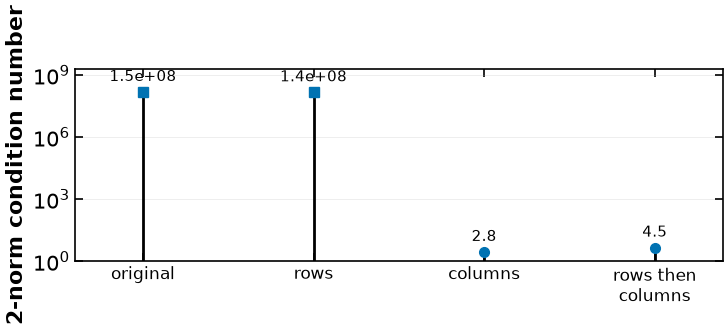

In [3]:
fig, ax = plt.subplots(figsize=(7.6,2.8))
rows = results["cases"]
for i,row in enumerate(rows):
    ax.plot([i,i],[1,row["condition_2"]],color="black",linestyle="-",linewidth=2)
    ax.plot(i,row["condition_2"],marker="s" if i<2 else "o",color="#0072B2",linestyle="none",ms=7)
    ax.annotate(f'{row["condition_2"]:.2g}', (i,row["condition_2"]),
                xytext=(0,8),textcoords="offset points",ha="center",fontsize=11)
ax.set_yscale("log")
ax.set(xticks=range(4),xticklabels=["original","rows","columns","rows then\ncolumns"],
       ylabel="2-norm condition number",ylim=(1,2e9),xlim=(-.4,3.4))
ax.tick_params(axis="x",labelsize=12)
ax.grid(axis="y",which="major",alpha=.25)
fig.tight_layout()
helper.save_figure(fig,"ctx-scaling-actual",quiet=True)
plt.show()

The original and recovered solution is $(10^5,10^{-3},1)^\mathsf T$. Column scaling gives coordinates $(1,1,1)^\mathsf T$; row-then-column scaling gives approximately $(.002,.001,.005)^\mathsf T$. The much smaller coordinates in the combined case are not different physical decisions. The 2-norm condition numbers are approximately $1.49\cdot10^8$, $1.44\cdot10^8$, $2.79$, and $4.50$. They compare conditioning of four represented systems; check the original residual after reversing the transformation. Choosing scales needs characteristic units and model knowledge, not only a blind largest-entry rule. Near dependent equations can remain ill conditioned after unit scaling.